# 07 · Live forecast: tomorrow's smog, from today's data

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/07_live_forecast.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebooks 01-06 build and test SAANS on history. This notebook uses it the way the proposal intends: **forecast the next 24 and 48 hours from data fetched right now**, during the 2026 smog season.

The live pipeline (`saans/live.py`) fetches the last four days of PM2.5 (OpenAQ), weather (Open-Meteo) and fires (NASA FIRMS near-real-time), cleans them with the rules of notebook 02, builds features with `saans/features.py`, and runs the saved models.

**First, a parity check.** A live forecast is only trustworthy if live features are computed exactly as in training. So before running live, we recompute the historical features with the live code and compare them with notebook 04's, and recompute a historical forecast and compare it with notebook 05's.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from saans.config import CITIES, PROCESSED, ROOT
from saans import features, live, viz
from saans.aqi import pm25_to_aqi

viz.use_style()
pd.set_option("display.width", 170)

## 1. Parity check: live code vs training code, on history

In [3]:
master = pd.read_parquet(PROCESSED / "master_hourly.parquet")
fires = pd.read_parquet(PROCESSED / "fires_clean.parquet")
cal = pd.read_parquet(PROCESSED / "event_calendar.parquet")
train_feats = pd.read_parquet(PROCESSED / "features.parquet")

rows = []
for city in CITIES:
    mine = features.compute(city, master[master.city == city], fires, cal)
    ref = train_feats[train_feats.city == city].set_index("time_utc")[features.FEATURES]
    mine = mine.set_index("time_utc")[features.FEATURES].loc[ref.index]
    diff = (mine - ref).abs()
    rows.append({"city": city, "rows": len(ref), "largest_difference": float(np.nanmax(diff.to_numpy())),
                 "features_with_any_difference": int((diff.max() > 1e-6).sum())})
parity = pd.DataFrame(rows)
parity

,city,rows,largest_difference,features_with_any_difference
0,lahore,53352,0.0,0
1,faisalabad,53352,0.0,0
2,multan,53352,0.0,0
3,islamabad,53352,0.0,0
4,karachi,53352,0.0,0


In [4]:
assert parity.largest_difference.max() < 1e-6, "live features differ from training features"
daily = pd.read_parquet(ROOT / "app" / "data" / "forecasts_daily.parquet")
check = train_feats[(train_feats.city == "lahore") & (train_feats.time_pkt == pd.Timestamp("2024-11-06 08:00", tz="Asia/Karachi"))]
mine = live.predict(check.reset_index(drop=True))
theirs = daily[(daily.city == "lahore") & (daily.time_pkt == pd.Timestamp("2024-11-06 08:00", tz="Asia/Karachi"))]
print(f"Lahore 6 Nov 2024 08:00: live code {mine.forecast_24h.iloc[0]:.2f} vs notebook 05 {theirs.forecast_24h.iloc[0]:.2f} ug/m3; "
      f"hazard {mine.hazard_prob.iloc[0]:.3f} vs {theirs.hazard_prob.iloc[0]:.3f}")
assert abs(mine.forecast_24h.iloc[0] - theirs.forecast_24h.iloc[0]) < 0.01

Lahore 6 Nov 2024 08:00: live code 392.47 vs notebook 05 392.47 ug/m3; hazard 0.903 vs 0.903


Every feature in every city matches to the sixth decimal, and the same forecast comes out. The live code is the training code.

## 2. Run the live forecast

Each step reports what it got, so the forecast never hides a missing input.

In [5]:
result = live.forecast()
status = result["status"]
print("Run at (UTC):", status["run_utc"])
print("Fires:", {k: v for k, v in status["fires"].items() if k != "errors"}, "| problems:", status["fires"].get("errors") or "none")
pd.DataFrame(status["cities"]).T

Run at (UTC): 2026-10-26 01:00:00+00:00
Fires: {'fresh': False, 'sources': [], 'detections': 0} | problems: ['VIIRS_SNPP_NRT: no answer', 'MODIS_NRT: no answer']


,sensors_reporting,sensor_hours_received,sensor_hours_kept,hours_with_pm25_last_24h,result,issued_at_utc
lahore,10,746,746,22,forecast issued,2026-10-26 01:00:00+00:00
faisalabad,10,842,832,22,forecast issued,2026-10-26 01:00:00+00:00
multan,10,674,674,22,forecast issued,2026-10-26 01:00:00+00:00
islamabad,10,939,939,22,forecast issued,2026-10-26 01:00:00+00:00
karachi,10,773,772,22,forecast issued,2026-10-26 01:00:00+00:00


In [6]:
fc = result["forecasts"]
if len(fc):
    table = fc.assign(city=fc.city.map(lambda c: CITIES[c].name), issued_pkt=fc.time_pkt.dt.strftime("%d %b %H:%M"),
                      aqi_24h=[int(pm25_to_aqi(v)) for v in fc.forecast_24h])
    display(table[["city", "issued_pkt", "pm25_24h", "forecast_24h", "q10", "q90", "aqi_24h", "risk_level", "hazard_prob", "forecast_48h"]]
            .round(1).rename(columns={"pm25_24h": "last_24h", "hazard_prob": "chance_AQI>300"}))

,city,issued_pkt,last_24h,forecast_24h,q10,q90,aqi_24h,risk_level,chance_AQI>300,forecast_48h
0,Lahore,26 Oct 06:00,95.8,97.1,60.2,158.8,180,Unhealthy,0.0,108.2
1,Faisalabad,26 Oct 06:00,74.5,76.1,47.9,135.4,165,Unhealthy,0.0,90.8
2,Multan,26 Oct 06:00,149.3,133.8,102.0,193.7,209,Very Unhealthy,0.0,115.0
3,Islamabad,26 Oct 06:00,53.4,59.0,44.8,76.7,153,Unhealthy,0.0,59.2
4,Karachi,26 Oct 06:00,68.9,68.9,37.6,123.0,160,Unhealthy,0.0,69.5


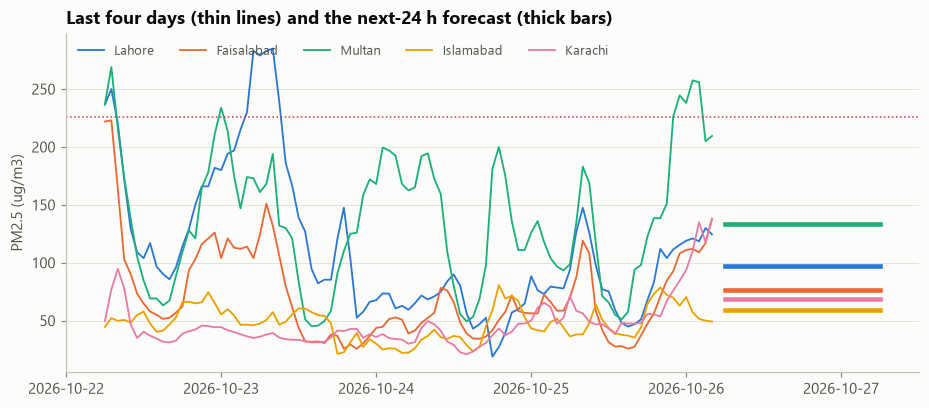

In [7]:
obs = result["observed"]
if len(fc):
    fig, ax = plt.subplots(figsize=(10, 4))
    for city in fc.city:
        o = obs[obs.city == city].sort_values("time_utc")
        r = fc[fc.city == city].iloc[0]
        t0 = r.time_utc
        ax.plot(o.time_utc.dt.tz_convert("Asia/Karachi"), o.pm25, color=viz.CITY_COLORS[city], lw=1.2, label=CITIES[city].name)
        ax.plot([t0.tz_convert("Asia/Karachi"), (t0 + pd.Timedelta(hours=24)).tz_convert("Asia/Karachi")], [r.forecast_24h] * 2,
                color=viz.CITY_COLORS[city], lw=3)
    ax.axhline(225.5, color=viz.STATUS["critical"], ls=":", lw=1)
    ax.set(title="Last four days (thin lines) and the next-24 h forecast (thick bars)", ylabel="PM2.5 (ug/m3)")
    ax.legend(loc="upper left", ncol=5, fontsize=8.5)
    plt.show()

## 3. Today's advisories and the snapshot

The AI Smog Explainer writes today's bilingual advisory for each city (same prompt and number check as notebook 06). The whole run is then frozen as a **snapshot** in `app/data/live_snapshot/`, which the dashboard shows when it has no API keys of its own.

In [8]:
from saans import advisory
advice = {}
for r in fc.itertuples():
    out = advisory.write(r.city, r.time_pkt.strftime("%Y-%m-%d"), r.forecast_24h, r.hazard_prob, r.top_drivers)
    advice[f"{r.city}|{r.time_pkt.strftime('%Y-%m-%d')}"] = out
live.save_snapshot(result)
(ROOT / "app" / "data" / "live_snapshot" / "advisories.json").write_text(json.dumps(advice, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"snapshot saved; {sum(a['source'] != 'template' for a in advice.values())} of {len(advice)} advisories written by the LLM")
for k, a in list(advice.items())[:1]:
    print(k); print(a["en"])

snapshot saved; 4 of 5 advisories written by the LLM
lahore|2026-10-26
The forecast 24-hour mean PM2.5 is 97 micrograms per cubic metre, and the US EPA AQI is 180 (Unhealthy), with a 0% chance that the next 24 hours are hazardous (AQI above 300).
This is mainly driven by the average pm2.5 over the last 24 hours, air pressure, and peak pm2.5 in the last 24 hours.
People should limit outdoor activity, and children, the elderly, and people with asthma must take extra care.
